# Scientific Data Visualization — Air Travel and Inequalities in Europe (2025)

**Research questions**

1. *Do wealthier countries fly more?* — GDP per capita (PPS) vs the share of residents who fly: **scatter plot, Pearson and Spearman correlations**.
2. *Are socially disadvantaged people less likely to fly?* — **AROPE vs non-AROPE** populations: **dumbbell plot and paired Wilcoxon test**.
3. *Do countries with higher income inequality have greater inequalities in air travel?* — **Gini coefficient vs the socioeconomic gap**: **scatter plot, Pearson and Spearman correlations**.
4. *Do urban residents fly more often than rural residents?* — **cities, towns and suburbs, and rural areas**: **heatmap, Friedman test and paired Wilcoxon test**.

**Unit of analysis: country.** These Eurostat percentages are **aggregate estimates**, not individual survey responses. The p-values describe cross-country associations or comparisons and do not account for all uncertainty in the EU-SILC survey. They do not establish causality.

**Required files (in the same folder)**:

- `europe_air_travel_2025_sans_faible_fiabilite.csv` (28 countries; selected observations flagged `u` have been excluded)
- `Persons by frequency of air travel in the last 12 months, household composition, degree of urbanisation and risk of poverty or social exclusion.csv` (original Eurostat air-travel export, needed for the urbanisation analysis)

The PNG figures and statistical summary will be saved automatically in the `visualisations` subfolder.


## 0 — Setup (one time only)

Run the following commands in a terminal:

```bash
pip install notebook pandas numpy scipy matplotlib
jupyter notebook
```

In VS Code, install the **Jupyter** extension, open this `.ipynb` file, and select your Python interpreter. Run the cells **from top to bottom**.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# IMPORTANT: only change this directory if the CSV files are not stored
# alongside the notebook or in a donnees_avion subfolder.
DATA_DIR = Path.cwd()
if not (DATA_DIR / "europe_air_travel_2025_sans_faible_fiabilite.csv").exists():
    DATA_DIR = DATA_DIR / "donnees_avion"

# If needed, replace the lines above with the full path on Windows:
# DATA_DIR = Path(r"C:\Users\desca\OneDrive - UCL\Erasmus cours - M2 Q1\scientific data visualization\final project\donnees_avion")

OUTPUT_DIR = DATA_DIR / "visualisations"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("CSV directory:", DATA_DIR)
print("Figures saved to:", OUTPUT_DIR)

CSV directory: c:\Users\desca\OneDrive - UCL\Erasmus cours - M2 Q1\scientific data visualization\final project\donnees_avion
Figures saved to: c:\Users\desca\OneDrive - UCL\Erasmus cours - M2 Q1\scientific data visualization\final project\donnees_avion\visualisations


## 1 — Load and validate the data

The merged dataset is used for analyses 1–3. The original Eurostat dataset is loaded only for analysis 4. The code checks the required columns, whether country codes are unique, and whether the relevant values are numeric.


In [ ]:
MASTER_FILE = "europe_air_travel_2025_sans_faible_fiabilite.csv"
AIR_FILE = "Persons by frequency of air travel in the last 12 months, household composition, degree of urbanisation and risk of poverty or social exclusion.csv"

def read_data(name):
    path = DATA_DIR / name
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}\nCheck DATA_DIR and the CSV filename.")
    return pd.read_csv(path, low_memory=False, dtype={"geo": "string"})

merged = read_data(MASTER_FILE)
required = ["geo", "air_total_pct", "air_arope_pct", "air_non_arope_pct",
            "social_gap_pp", "gini", "gdp_per_capita_pps"]
missing = set(required) - set(merged.columns)
if missing:
    raise ValueError(f"Missing columns in the merged CSV: {missing}")

# If the file is not strictly filtered, apply the quality flag explicitly.
if "included_in_strict_analysis" in merged.columns:
    merged = merged.loc[
        merged["included_in_strict_analysis"].astype(str).str.lower() == "true"
    ].copy()

for col in required[1:]:
    merged[col] = pd.to_numeric(merged[col], errors="coerce")
merged = merged.dropna(subset=required).copy()
if merged["geo"].duplicated().any():
    raise ValueError("Multiple rows for the same country: check the merge.")

assert merged["air_total_pct"].between(0, 100).all()
assert merged["air_arope_pct"].between(0, 100).all()
assert merged["air_non_arope_pct"].between(0, 100).all()
assert merged["gini"].between(0, 100).all()

print(f"Countries analysed: {len(merged)}")
print("Country codes:", ", ".join(sorted(merged["geo"].tolist())))
print(merged[["geo", "air_total_pct", "gdp_per_capita_pps", "gini", "social_gap_pp"]].round(1).to_string(index=False))
#print(merged[["geo", "air_total_pct", "gdp_per_capita_pps", "gini", "social_gap_pp"]].head().round(1).to_string(index=False))
# Possible extension: visualise the table and highlight the countries with the highest and lowest values.

Countries analysed: 28
Country codes: AT, BE, BG, CY, DE, DK, EE, EL, ES, FI, FR, HR, HU, IE, IT, LT, LU, LV, MT, NL, NO, PL, PT, RO, RS, SE, SI, SK
geo  air_total_pct  gdp_per_capita_pps  gini  social_gap_pp
 AT           33.3             49398.0  27.4           10.6
 BE           39.2             47597.5  23.4           21.0
 BG           11.0             28433.4  37.7            9.2
 CY           46.9             43011.9  31.2           33.3
 DE           33.6             48621.8  30.1           14.4
 DK           54.7             53940.8  28.2           15.6
 EE           42.7             33279.1  30.9           29.1
 EL           20.1             29083.4  31.6           19.1
 ES           33.3             38161.7  30.8           15.2
 FI           38.4             42086.6  27.1           17.9
 FR           32.7             40716.0  30.4           14.2
 HR           11.6             32736.1  28.5            8.3
 HU           16.6             31815.6  29.5           12.8
 IE        

### Shared functions: save plots and analyse correlations

We calculate both **Pearson** (linear association) and **Spearman** (rank-based monotonic association) correlations. The fitted line in the figure is a **descriptive** linear regression, not evidence of causality.


In [3]:
results = []

def save_and_show(fig, filename):
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()

def scatter_correlation(data, x_col, y_col, x_label, y_label, title, filename):
    d = data[["geo", x_col, y_col]].dropna().copy()
    x = d[x_col].to_numpy(dtype=float)
    y = d[y_col].to_numpy(dtype=float)
    pearson_r, pearson_p = stats.pearsonr(x, y)
    spearman_rho, spearman_p = stats.spearmanr(x, y)

    fig, ax = plt.subplots(figsize=(9, 6))
    ax.scatter(x, y, s=52, alpha=0.85)
    for _, row in d.iterrows():
        ax.annotate(row["geo"], (row[x_col], row[y_col]),
                    xytext=(4, 3), textcoords="offset points", fontsize=8)
    slope, intercept = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, slope * x_line + intercept, linestyle="--", label="Linear trend")
    ax.set(title=title, xlabel=x_label, ylabel=y_label)
    ax.grid(alpha=0.25)
    ax.legend(loc="best")
    ax.text(0.02, 0.98,
            f"n = {len(d)}\nPearson r = {pearson_r:.3f} (p = {pearson_p:.3g})"
            f"\nSpearman ρ = {spearman_rho:.3f} (p = {spearman_p:.3g})",
            transform=ax.transAxes, va="top", fontsize=9)
    save_and_show(fig, filename)

    print(f"{title}: n={len(d)}")
    print(f"  Pearson : r={pearson_r:.3f}, p={pearson_p:.4g}")
    print(f"  Spearman: rho={spearman_rho:.3f}, p={spearman_p:.4g}")
    results.extend([
        {"analysis": title, "test": "Pearson", "n_countries": len(d), "statistic": pearson_r, "p_value": pearson_p},
        {"analysis": title, "test": "Spearman", "n_countries": len(d), "statistic": spearman_rho, "p_value": spearman_p},
    ])
    return d

## 2 — Question 1: Do wealthier countries fly more?

- **X** = GDP per capita in PPS (`gdp_per_capita_pps`)
- **Y** = percentage of residents who flew at least once (`air_total_pct`)
- **H₀**: no correlation between these two country-level indicators.

Be mindful of unusual cases such as Luxembourg and Ireland: GDP per capita is not the same as the personal income of air travellers.


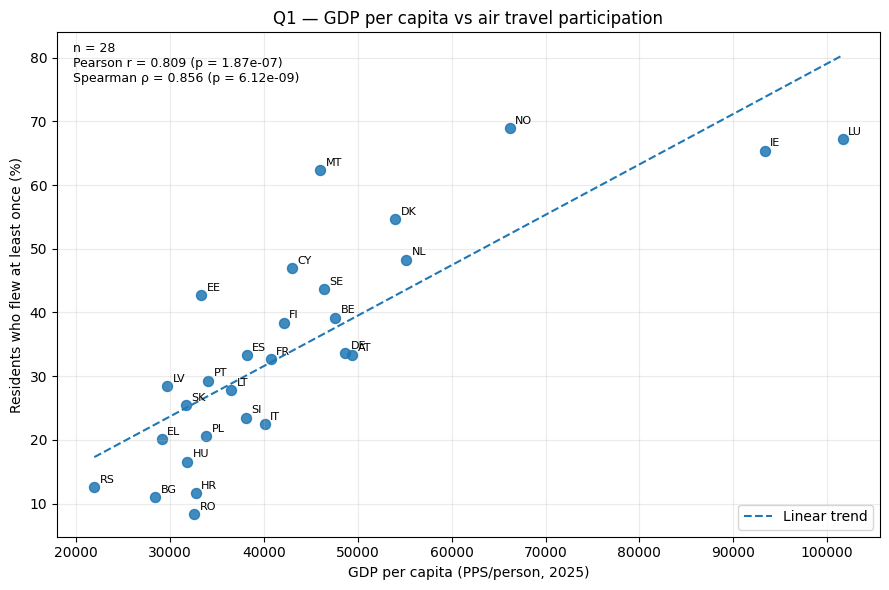

Q1 — GDP per capita vs air travel participation: n=28
  Pearson : r=0.809, p=1.875e-07
  Spearman: rho=0.856, p=6.115e-09


In [ ]:
q1 = scatter_correlation(
    merged, "gdp_per_capita_pps", "air_total_pct",
    "GDP per capita (PPS/person, 2025)", "Residents who flew at least once (%)",
    "Q1 — GDP per capita vs air travel participation",
    "01_gdp_vs_air_travel.png"
)
# TODO: consider adding a clearer legend or explanatory note to make the chart easier to interpret.

## 3 — Question 2: Are socially disadvantaged people less likely to fly?

Within **each country**, we compare air-travel participation among **AROPE** (at risk of poverty or social exclusion) and **non-AROPE** populations. The connected-dot (**dumbbell**) plot makes the differences visible.

Test: **paired Wilcoxon signed-rank test**, because both rates refer to the same country. This test compares country-level gaps, **not individual survey responses**. It does not account for Eurostat sampling uncertainty.


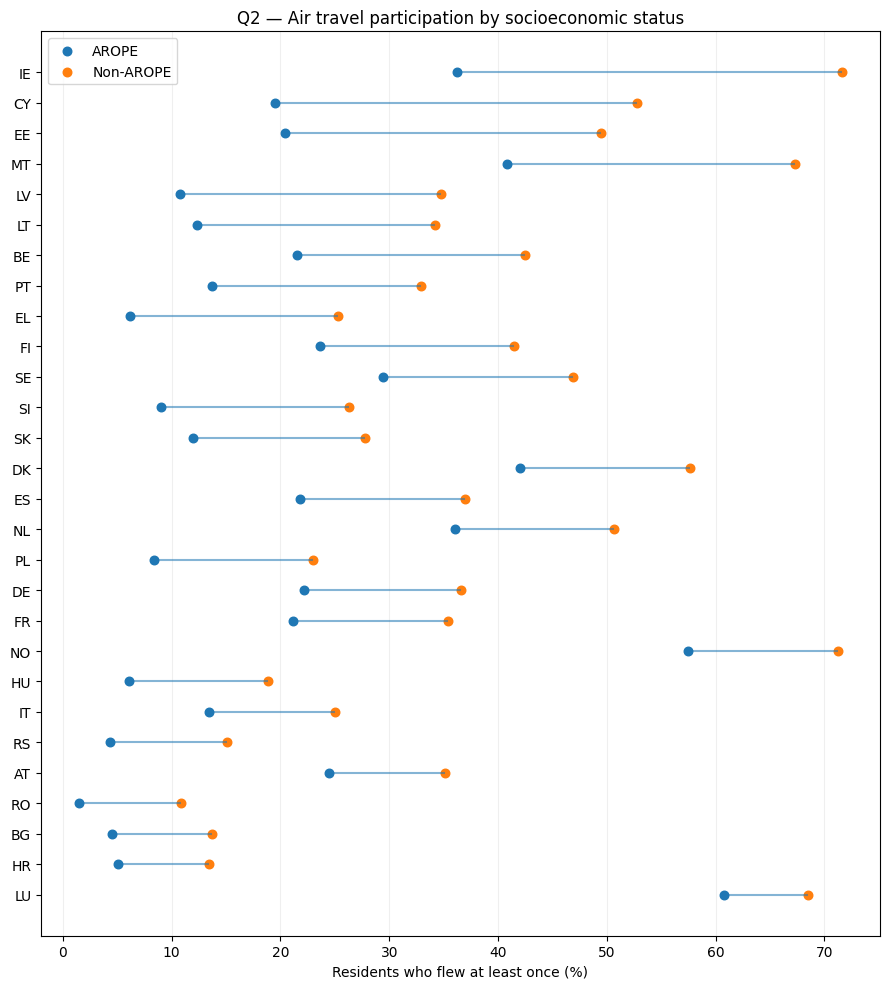

Number of paired countries: 28
Median gap (non-AROPE minus AROPE): 15.40 percentage points
Countries where non-AROPE > AROPE: 28/28
Wilcoxon : W=0.000, p=7.451e-09


In [5]:
q2 = merged[["geo", "air_arope_pct", "air_non_arope_pct", "social_gap_pp"]].copy()
q2 = q2.sort_values("social_gap_pp")
y_pos = np.arange(len(q2))

fig, ax = plt.subplots(figsize=(9, 10))
ax.hlines(y_pos, q2["air_arope_pct"], q2["air_non_arope_pct"], alpha=0.55)
ax.scatter(q2["air_arope_pct"], y_pos, label="AROPE", s=38)
ax.scatter(q2["air_non_arope_pct"], y_pos, label="Non-AROPE", s=38)
ax.set_yticks(y_pos, q2["geo"])
ax.set(xlabel="Residents who flew at least once (%)",
       title="Q2 — Air travel participation by socioeconomic status")
ax.legend()
ax.grid(axis="x", alpha=0.2)
save_and_show(fig, "02_arope_vs_non_arope.png")

w = stats.wilcoxon(q2["air_non_arope_pct"], q2["air_arope_pct"], alternative="two-sided")
gap = q2["air_non_arope_pct"] - q2["air_arope_pct"]
print(f"Number of paired countries: {len(q2)}")
print(f"Median gap (non-AROPE minus AROPE): {gap.median():.2f} percentage points")
print(f"Countries where non-AROPE > AROPE: {(gap > 0).sum()}/{len(gap)}")
print(f"Wilcoxon : W={w.statistic:.3f}, p={w.pvalue:.4g}")
results.append({"analysis":"Q2 — AROPE vs non-AROPE", "test":"Wilcoxon paired",
                "n_countries":len(q2), "statistic":w.statistic, "p_value":w.pvalue})

## 4 — Question 3: Does greater income inequality correspond to a larger social air-travel gap?

- **X** = Gini coefficient (0–100; higher values indicate greater income inequality)
- **Y** = air-travel participation gap in **percentage points** (`social_gap_pp`)
- **H₀**: no country-level correlation between these two indicators.

A non-significant result is still scientifically interesting: it may suggest that the Gini coefficient alone does not explain the variation in observed socioeconomic gaps.


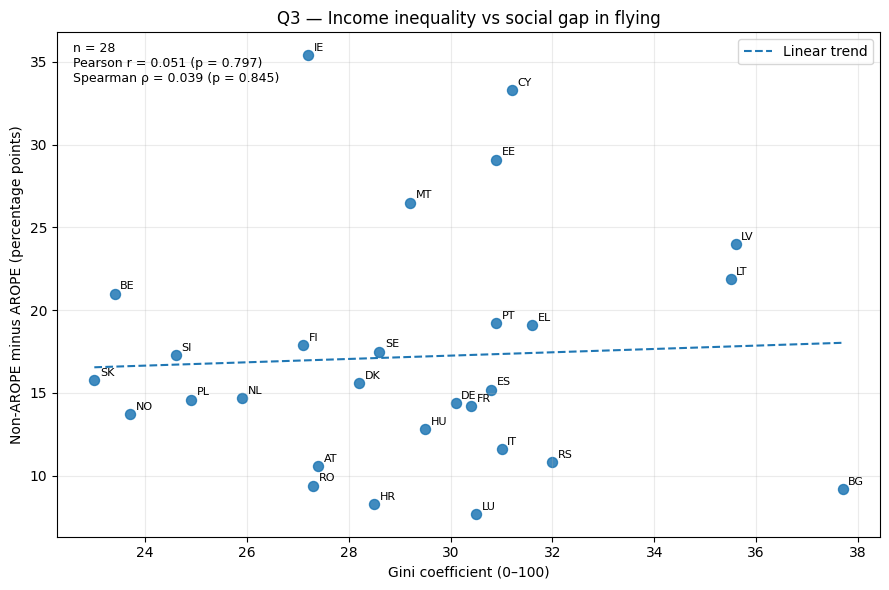

Q3 — Income inequality vs social gap in flying: n=28
  Pearson : r=0.051, p=0.7968
  Spearman: rho=0.039, p=0.8454


In [6]:
q3 = scatter_correlation(
    merged, "gini", "social_gap_pp",
    "Gini coefficient (0–100)", "Non-AROPE minus AROPE (percentage points)",
    "Q3 — Income inequality vs social gap in flying",
    "03_gini_vs_social_gap.png"
)

## 5 — Question 4: Do urban residents fly more often than rural residents?

**The merged file alone is insufficient for this analysis.** We load the **original** Eurostat CSV and select:

- `yn_arope = TOTAL`: all socioeconomic groups;
- `hhcomp = TOTAL`: all household types;
- `frequenc = NM12`: did not fly in the past 12 months;
- `deg_urb`: `DEG1` (cities), `DEG2` (towns and suburbs), `DEG3` (rural areas);
- `unit = PC`, `TIME_PERIOD = 2025`, and the **same 28 countries**.

Participation is calculated as `100 − OBS_VALUE`. For this analysis, we exclude **only** observations whose quality flag contains `u`, then retain countries with data for all three areas. This is not equivalent to excluding every country with a `u` flag anywhere in the full dataset.


In [7]:
air_original = read_data(AIR_FILE)
sub = air_original.loc[
    (air_original["geo"].isin(merged["geo"])) &
    (air_original["TIME_PERIOD"] == 2025) &
    (air_original["yn_arope"] == "TOTAL") &
    (air_original["hhcomp"] == "TOTAL") &
    (air_original["frequenc"] == "NM12") &
    (air_original["unit"] == "PC") &
    (air_original["deg_urb"].isin(["DEG1", "DEG2", "DEG3"])),
    ["geo", "deg_urb", "OBS_VALUE", "OBS_FLAG"]
].copy()

if sub.duplicated(["geo", "deg_urb"]).any():
    raise ValueError("Duplicate country × urbanisation rows in the Eurostat export")
sub["OBS_FLAG"] = sub["OBS_FLAG"].fillna("").astype(str)
sub["OBS_VALUE"] = pd.to_numeric(sub["OBS_VALUE"], errors="coerce")
sub = sub.loc[~sub["OBS_FLAG"].str.contains("u", case=False, na=False)].copy()
sub["air_pct"] = 100 - sub["OBS_VALUE"]
urban = sub.pivot(index="geo", columns="deg_urb", values="air_pct")
urban = urban.reindex(columns=["DEG1", "DEG2", "DEG3"]).dropna().copy()
urban.columns = ["Cities", "Towns/suburbs", "Rural"]
print(f"Countries with all three comparable areas: {len(urban)}")
print("Median participation (%) by area:")
print(urban.median().round(2))

Countries with all three comparable areas: 28
Median participation (%) by area:
Cities           40.45
Towns/suburbs    29.80
Rural            23.70
dtype: float64


### Urbanisation heatmap

Each cell shows the **percentage of residents in that type of area who flew at least once**, for a given country. Countries are sorted by the cities-minus-rural participation gap.


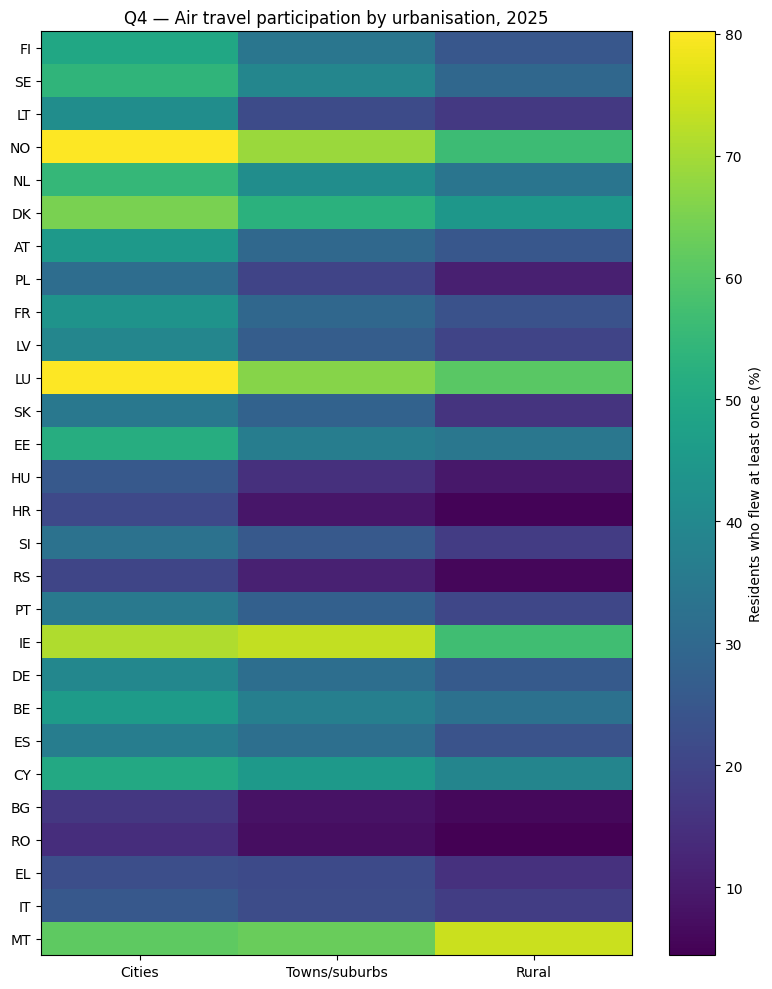

In [8]:
urban_plot = urban.assign(city_minus_rural=urban["Cities"] - urban["Rural"])
urban_plot = urban_plot.sort_values("city_minus_rural", ascending=False).drop(columns="city_minus_rural")
fig, ax = plt.subplots(figsize=(8, 10))
im = ax.imshow(urban_plot.to_numpy(), aspect="auto")
ax.set_xticks(range(3), urban_plot.columns)
ax.set_yticks(range(len(urban_plot)), urban_plot.index)
ax.set(title="Q4 — Air travel participation by urbanisation, 2025")
cb = fig.colorbar(im, ax=ax)
cb.set_label("Residents who flew at least once (%)")
save_and_show(fig, "04_urbanisation_heatmap.png")

### Paired tests and cities–rural differences

- **Friedman test** compares all three urbanisation categories across the **same countries**.
- **Paired Wilcoxon test** specifically examines the *cities vs rural* difference (a prespecified comparison).

These tests do not directly measure differences between individuals. If you subsequently test all three pairwise comparisons, you should adjust for multiple testing (e.g. using Holm's method).


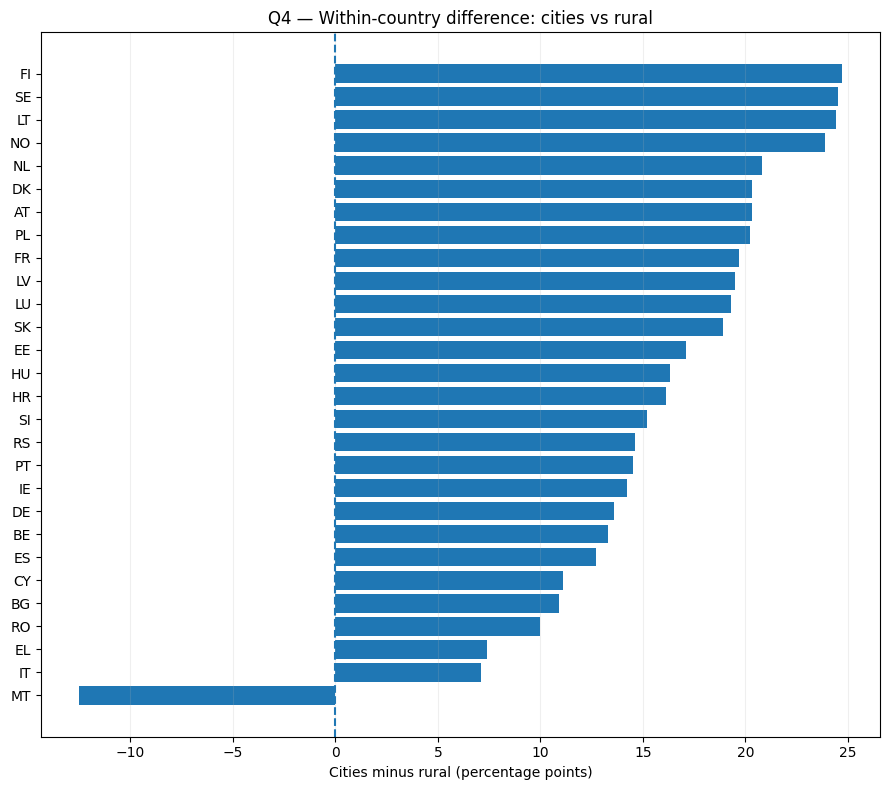

Friedman: chi²=46.500, p=7.992e-11
Wilcoxon cities vs rural: W=6.000, p=1.043e-07
Median gap (cities minus rural): 16.20 percentage points
Countries where cities > rural: 27 / 28


In [9]:
friedman = stats.friedmanchisquare(urban["Cities"], urban["Towns/suburbs"], urban["Rural"])
ur_wilcoxon = stats.wilcoxon(urban["Cities"], urban["Rural"], alternative="two-sided")
diff = (urban["Cities"] - urban["Rural"]).sort_values()

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(diff.index, diff.values)
ax.axvline(0, linestyle="--")
ax.set(xlabel="Cities minus rural (percentage points)",
       title="Q4 — Within-country difference: cities vs rural")
ax.grid(axis="x", alpha=0.2)
save_and_show(fig, "05_cities_vs_rural_differences.png")

print(f"Friedman: chi²={friedman.statistic:.3f}, p={friedman.pvalue:.4g}")
print(f"Wilcoxon cities vs rural: W={ur_wilcoxon.statistic:.3f}, p={ur_wilcoxon.pvalue:.4g}")
print(f"Median gap (cities minus rural): {diff.median():.2f} percentage points")
print(f"Countries where cities > rural: {(diff > 0).sum()} / {len(diff)}")
results.extend([
    {"analysis":"Q4 — Urbanisation (3 groups)", "test":"Friedman",
     "n_countries":len(urban), "statistic":friedman.statistic, "p_value":friedman.pvalue},
    {"analysis":"Q4 — Cities vs rural", "test":"Wilcoxon paired",
     "n_countries":len(urban), "statistic":ur_wilcoxon.statistic, "p_value":ur_wilcoxon.pvalue},
])

## 6 — Export results and interpret the findings

The program creates a summary table of statistical tests. **Do not interpret** a significant p-value as proof that one phenomenon causes another: confounding factors may exist (geography, ticket prices, rail accessibility, household income, etc.).

P-values for cross-country correlations rely on inferential assumptions that may be questionable for a non-random set of countries. The Wilcoxon and Friedman tests use estimated participation rates without incorporating the survey standard errors. Treat these findings as exploratory.

**Regarding CO₂:** the Eurostat dataset records whether residents flew, not the amount of CO₂ they emitted. A separate data source would be needed to estimate the emissions attributable to frequent flyers.


In [10]:
summary = pd.DataFrame(results)
summary.to_csv(OUTPUT_DIR / "statistical_summary.csv", index=False)
print(summary.round(5).to_string(index=False))
print("\nGenerated files:")
for path in sorted(OUTPUT_DIR.glob("*.png")):
    print(" -", path.name)
print(" - statistical_summary.csv")

                                       analysis            test  n_countries  statistic  p_value
Q1 — GDP per capita vs air travel participation         Pearson           28    0.80906  0.00000
Q1 — GDP per capita vs air travel participation        Spearman           28    0.85644  0.00000
                        Q2 — AROPE vs non-AROPE Wilcoxon paired           28    0.00000  0.00000
 Q3 — Income inequality vs social gap in flying         Pearson           28    0.05096  0.79678
 Q3 — Income inequality vs social gap in flying        Spearman           28    0.03859  0.84541
                   Q4 — Urbanisation (3 groups)        Friedman           28   46.50000  0.00000
                           Q4 — Cities vs rural Wilcoxon paired           28    6.00000  0.00000

Generated files:
 - 01_gdp_vs_air_travel.png
 - 02_arope_vs_non_arope.png
 - 03_gini_vs_social_gap.png
 - 04_urbanisation_heatmap.png
 - 05_cities_vs_rural_differences.png
 - statistical_summary.csv
